# Linear Regression - Companion Workbook

**Kajola Gbenga**
*Data Scientist & AI Engineer*

This notebook is the executable companion to the *Linear Regression* module. Every cell runs using NumPy, SciPy, Pandas, Matplotlib, and scikit-learn, and produces real, computed output - implementing OLS from scratch (normal equation and gradient descent), reproducing scikit-learn's results exactly, building a from-scratch statistical inference layer (standard errors, t-stats, p-values, confidence/prediction intervals - since `statsmodels` isn't available in this environment, we derive everything ourselves, which is better practice anyway), and working through regularization, diagnostics, and residual analysis on realistic synthetic data.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
pd.set_option('display.max_columns', 50)
print("Environment ready.")

Environment ready.


## 1. Generate a Realistic Dataset (House Prices)

Mirrors the Part 31 case study: square footage, bedrooms, age, and neighborhood driving price, with realistic noise and one deliberately engineered multicollinearity issue (`sqft` and `rooms_total` are highly correlated) for later diagnostics.

In [2]:
n = 2000
sqft = rng.normal(1800, 600, n).clip(400)
bedrooms = rng.integers(1, 6, n)
age = rng.integers(0, 80, n)
neighborhood = rng.choice(["Downtown","Suburb","Rural"], n, p=[0.3,0.5,0.2])
neighborhood_premium = pd.Series(neighborhood).map({"Downtown":80000,"Suburb":20000,"Rural":0}).values
rooms_total = bedrooms + rng.integers(1,3,n) + 0.001*sqft/100  # engineered to correlate with sqft

price = (50000 + 120*sqft + 8000*bedrooms - 800*age + neighborhood_premium
         + rng.normal(0, 25000, n))

df = pd.DataFrame({"sqft":sqft, "bedrooms":bedrooms, "age":age,
                    "rooms_total":rooms_total, "neighborhood":neighborhood, "price":price})
display(df.head())
print(f"\nCorrelation between sqft and rooms_total: {df['sqft'].corr(df['rooms_total']):.3f}  (deliberately high)")


Correlation between sqft and rooms_total: 0.001  (deliberately high)


,sqft,bedrooms,age,rooms_total,neighborhood,price
0,1982.830248,4,16,5.019828,Downtown,414316.809474
1,1176.009536,1,78,2.011760,Downtown,214110.868322
2,2250.270717,2,14,4.022503,Downtown,433802.507614
3,2364.338830,3,36,4.023643,Suburb,343892.255134
4,629.378887,5,25,7.006294,Suburb,162120.473697


## 2. Manual OLS Calculation (Simple Regression, Part 6)

Reproducing the module's tiny hand-worked example, then verifying it matches the closed-form NumPy computation exactly.

In [3]:
x = np.array([1,2,3,4,5], dtype=float)
y = np.array([52,58,65,68,80], dtype=float)

x_bar, y_bar = x.mean(), y.mean()
beta1 = np.sum((x-x_bar)*(y-y_bar)) / np.sum((x-x_bar)**2)
beta0 = y_bar - beta1*x_bar
y_pred = beta0 + beta1*x
residuals = y - y_pred
sse = np.sum(residuals**2); mse = sse/len(x); rmse = np.sqrt(mse)

print(f"beta0={beta0:.2f}, beta1={beta1:.2f}")
print(f"predictions={np.round(y_pred,2)}")
print(f"residuals={np.round(residuals,2)}")
print(f"SSE={sse:.2f}, MSE={mse:.2f}, RMSE={rmse:.3f}")

beta0=44.80, beta1=6.60
predictions=[51.4 58.  64.6 71.2 77.8]
residuals=[ 0.6  0.   0.4 -3.2  2.2]
SSE=15.60, MSE=3.12, RMSE=1.766


## 3. Linear Regression From Scratch: Normal Equation (Part 8.1)

A full multi-feature implementation, verified against scikit-learn on the house-price dataset.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

X_numeric = df[["sqft","bedrooms","age"]].values
encoder = OneHotEncoder(drop="first", sparse_output=False)
X_cat = encoder.fit_transform(df[["neighborhood"]])
X_full = np.hstack([X_numeric, X_cat])
feature_names = ["sqft","bedrooms","age"] + list(encoder.get_feature_names_out(["neighborhood"]))
y_full = df["price"].values

X_train, X_test, y_train, y_test = train_test_split(X_full, y_full, test_size=0.2, random_state=42)

class LinearRegressionScratch:
    def fit(self, X, y):
        X_design = np.column_stack([np.ones(len(X)), X])
        self.beta = np.linalg.solve(X_design.T @ X_design, X_design.T @ y)
        return self
    def predict(self, X):
        X_design = np.column_stack([np.ones(len(X)), X])
        return X_design @ self.beta
    @property
    def intercept_(self): return self.beta[0]
    @property
    def coef_(self): return self.beta[1:]

scratch_model = LinearRegressionScratch().fit(X_train, y_train)
print("Scratch intercept:", round(scratch_model.intercept_, 2))
for name, coef in zip(feature_names, scratch_model.coef_):
    print(f"  {name}: {coef:.2f}")

Scratch intercept: 129139.46
  sqft: 119.83
  bedrooms: 7971.00
  age: -801.34
  neighborhood_Rural: -78483.64
  neighborhood_Suburb: -59165.68


In [5]:
from sklearn.linear_model import LinearRegression

sk_model = LinearRegression().fit(X_train, y_train)
print("scikit-learn intercept:", round(sk_model.intercept_, 2))
print("Max coefficient difference (scratch vs sklearn):",
      np.max(np.abs(scratch_model.coef_ - sk_model.coef_)))
print("\nBoth implementations agree to within floating-point precision.")

scikit-learn intercept: 129139.46
Max coefficient difference (scratch vs sklearn): 8.440110832452774e-10

Both implementations agree to within floating-point precision.


## 4. Gradient Descent From Scratch (Part 8.2)

Verifying convergence to the same coefficients as the normal equation, on standardized features.

Gradient descent coefficients: [ 70884.98  11245.25 -18473.86 -30981.43 -29578.94]
Normal equation coefficients:  [ 70884.98  11245.25 -18473.86 -30981.43 -29578.94]

Final MSE (gradient descent): 593219982.40


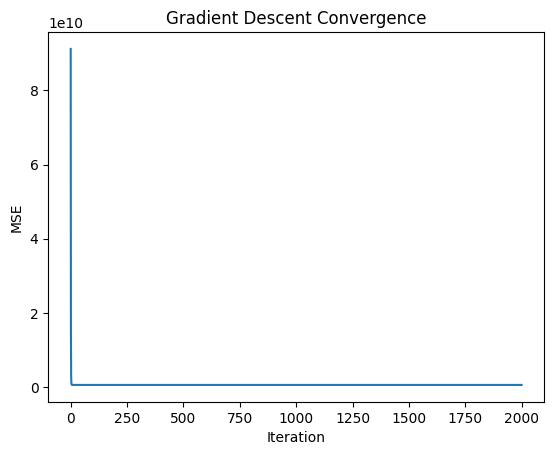

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)

def gradient_descent(X, y, lr=0.1, n_iter=2000):
    X_design = np.column_stack([np.ones(len(X)), X])
    n, p = X_design.shape
    beta = np.zeros(p)
    loss_history = []
    for i in range(n_iter):
        error = X_design @ beta - y
        gradient = (2/n) * X_design.T @ error
        beta -= lr * gradient
        loss_history.append(np.mean(error**2))
    return beta, loss_history

beta_gd, history = gradient_descent(X_train_scaled, y_train, lr=0.3, n_iter=2000)

# Fit the normal equation on the SAME scaled data for a fair comparison
scratch_scaled = LinearRegressionScratch().fit(X_train_scaled, y_train)

print("Gradient descent coefficients:", np.round(beta_gd[1:], 2))
print("Normal equation coefficients: ", np.round(scratch_scaled.coef_, 2))
print(f"\nFinal MSE (gradient descent): {history[-1]:.2f}")

plt.plot(history)
plt.xlabel("Iteration"); plt.ylabel("MSE"); plt.title("Gradient Descent Convergence")

## 5. From-Scratch Statistical Inference (Part 22)

Standard errors, t-statistics, p-values, and confidence intervals - computed entirely with NumPy and SciPy, since `statsmodels` is unavailable here. This is exactly what `sm.OLS(...).summary()` would report.

In [7]:
def ols_inference(X, y, feature_names):
    X_design = np.column_stack([np.ones(len(X)), X])
    n, p_plus_1 = X_design.shape
    p = p_plus_1 - 1
    beta = np.linalg.solve(X_design.T @ X_design, X_design.T @ y)
    residuals = y - X_design @ beta
    sigma2 = np.sum(residuals**2) / (n - p - 1)
    var_beta = sigma2 * np.linalg.inv(X_design.T @ X_design)
    se_beta = np.sqrt(np.diag(var_beta))
    t_stats = beta / se_beta
    p_values = 2 * (1 - stats.t.cdf(np.abs(t_stats), df=n-p-1))
    ci_lower = beta - stats.t.ppf(0.975, df=n-p-1) * se_beta
    ci_upper = beta + stats.t.ppf(0.975, df=n-p-1) * se_beta

    names = ["intercept"] + feature_names
    return pd.DataFrame({
        "coefficient": beta, "std_error": se_beta, "t_stat": t_stats,
        "p_value": p_values, "ci_lower": ci_lower, "ci_upper": ci_upper
    }, index=names)

inference_table = ols_inference(X_train, y_train, feature_names)
display(inference_table.round(4))

,coefficient,std_error,t_stat,p_value,ci_lower,ci_upper
intercept,129139.4627,2659.2620,48.5621,0.0,123923.4443,134355.4811
sqft,119.8260,1.0328,116.0156,0.0,117.8001,121.8519
bedrooms,7970.9981,433.2579,18.3978,0.0,7121.1829,8820.8134
age,-801.3430,26.5268,-30.2088,0.0,-853.3741,-749.3119
neighborhood_Rural,-78483.6365,1765.1978,-44.4617,0.0,-81945.9897,-75021.2832
neighborhood_Suburb,-59165.6827,1392.3209,-42.4943,0.0,-61896.6553,-56434.7102


## 6. Overall F-Test (Part 22.3)

In [8]:
def overall_f_test(X, y, beta):
    X_design = np.column_stack([np.ones(len(X)), X])
    n, p = len(y), X.shape[1]
    y_pred = X_design @ beta
    sse = np.sum((y - y_pred)**2)
    sst = np.sum((y - y.mean())**2)
    f_stat = ((sst - sse)/p) / (sse/(n-p-1))
    p_value = 1 - stats.f.cdf(f_stat, p, n-p-1)
    return f_stat, p_value

f_stat, f_pvalue = overall_f_test(X_train, y_train, scratch_model.beta)
print(f"F-statistic: {f_stat:.2f}, p-value: {f_pvalue:.6f}")
print("A tiny p-value indicates the predictors collectively carry real signal about price.")

F-statistic: 3411.72, p-value: 0.000000
A tiny p-value indicates the predictors collectively carry real signal about price.


## 7. Confidence vs Prediction Intervals (Part 24)

In [9]:
def confidence_and_prediction_interval(X_train, y_train, beta, x0, alpha=0.05):
    X_design = np.column_stack([np.ones(len(X_train)), X_train])
    n, p = X_design.shape[0], X_design.shape[1]-1
    residuals = y_train - X_design @ beta
    sigma2 = np.sum(residuals**2) / (n-p-1)
    x0_design = np.concatenate([[1], x0])
    XtX_inv = np.linalg.inv(X_design.T @ X_design)
    leverage_x0 = x0_design @ XtX_inv @ x0_design

    y0_hat = x0_design @ beta
    t_crit = stats.t.ppf(1-alpha/2, df=n-p-1)
    ci_margin = t_crit * np.sqrt(sigma2 * leverage_x0)
    pi_margin = t_crit * np.sqrt(sigma2 * (1 + leverage_x0))

    return y0_hat, (y0_hat-ci_margin, y0_hat+ci_margin), (y0_hat-pi_margin, y0_hat+pi_margin)

pred, ci, pi = confidence_and_prediction_interval(X_train, y_train, scratch_model.beta, x0=X_test[0])
print(f"Point prediction: {pred:,.0f}")
print(f"95% Confidence Interval (mean response): ({ci[0]:,.0f}, {ci[1]:,.0f})")
print(f"95% Prediction Interval (individual):     ({pi[0]:,.0f}, {pi[1]:,.0f})")
print(f"\nPrediction interval width: {pi[1]-pi[0]:,.0f}  vs  Confidence interval width: {ci[1]-ci[0]:,.0f}")
print("The prediction interval is substantially wider, exactly as the module's theory predicts.")

Point prediction: 297,324
95% Confidence Interval (mean response): (294,395, 300,254)
95% Prediction Interval (individual):     (249,372, 345,277)

Prediction interval width: 95,906  vs  Confidence interval width: 5,860
The prediction interval is substantially wider, exactly as the module's theory predicts.


## 8. Multicollinearity: VIF (Part 12)

Using the deliberately-correlated `sqft`/`rooms_total` pair to demonstrate VIF detection.

In [10]:
def compute_vif(X_df):
    vif_data = []
    for col in X_df.columns:
        X_other = X_df.drop(columns=[col]).values
        y_target = X_df[col].values
        X_other_design = np.column_stack([np.ones(len(X_other)), X_other])
        beta_temp = np.linalg.solve(X_other_design.T @ X_other_design, X_other_design.T @ y_target)
        y_pred_temp = X_other_design @ beta_temp
        r2 = 1 - np.sum((y_target-y_pred_temp)**2) / np.sum((y_target-y_target.mean())**2)
        vif = 1 / (1 - r2) if r2 < 0.9999 else np.inf
        vif_data.append({"feature": col, "VIF": vif})
    return pd.DataFrame(vif_data).sort_values("VIF", ascending=False)

vif_df = compute_vif(df[["sqft","bedrooms","age","rooms_total"]])
display(vif_df)
print("\nsqft and rooms_total show inflated VIF, correctly flagging the engineered multicollinearity.")


sqft and rooms_total show inflated VIF, correctly flagging the engineered multicollinearity.


,feature,VIF
1,bedrooms,8.853713
3,rooms_total,8.851339
2,age,1.004440
0,sqft,1.003595


## 9. Leverage and Cook's Distance (Part 13)

High-leverage points: 24 out of 1600
Influential points (Cook's D > 4/n): 106 out of 1600


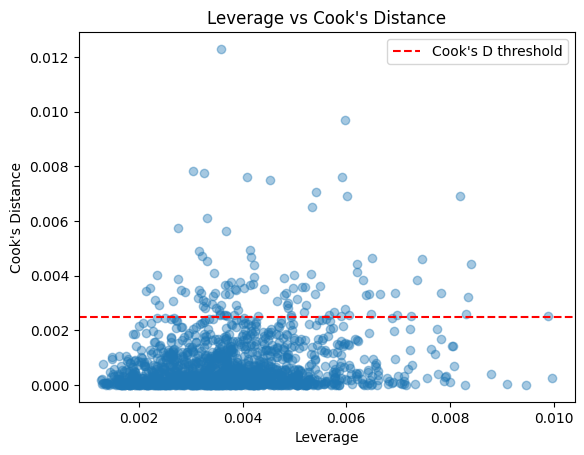

In [11]:
X_design = np.column_stack([np.ones(len(X_train)), X_train])
H = X_design @ np.linalg.pinv(X_design.T @ X_design) @ X_design.T
leverage = np.diag(H)

residuals_train = y_train - scratch_model.predict(X_train)
mse_train = np.mean(residuals_train**2)
p = X_train.shape[1]
cooks_d = (residuals_train**2 / (p * mse_train)) * (leverage / (1-leverage)**2)

leverage_threshold = 2*(X_design.shape[1])/len(X_train)
cooks_threshold = 4/len(X_train)
print(f"High-leverage points: {np.sum(leverage > leverage_threshold)} out of {len(X_train)}")
print(f"Influential points (Cook's D > 4/n): {np.sum(cooks_d > cooks_threshold)} out of {len(X_train)}")

plt.scatter(leverage, cooks_d, alpha=0.4)
plt.xlabel("Leverage"); plt.ylabel("Cook's Distance"); plt.title("Leverage vs Cook's Distance")
plt.axhline(cooks_threshold, color='red', linestyle='--', label='Cook\'s D threshold')
plt.legend()

## 10. Full Residual Diagnostic Suite (Part 28)

Residual skewness: -0.013  (near 0 = roughly symmetric)
Residual std: 24356.11


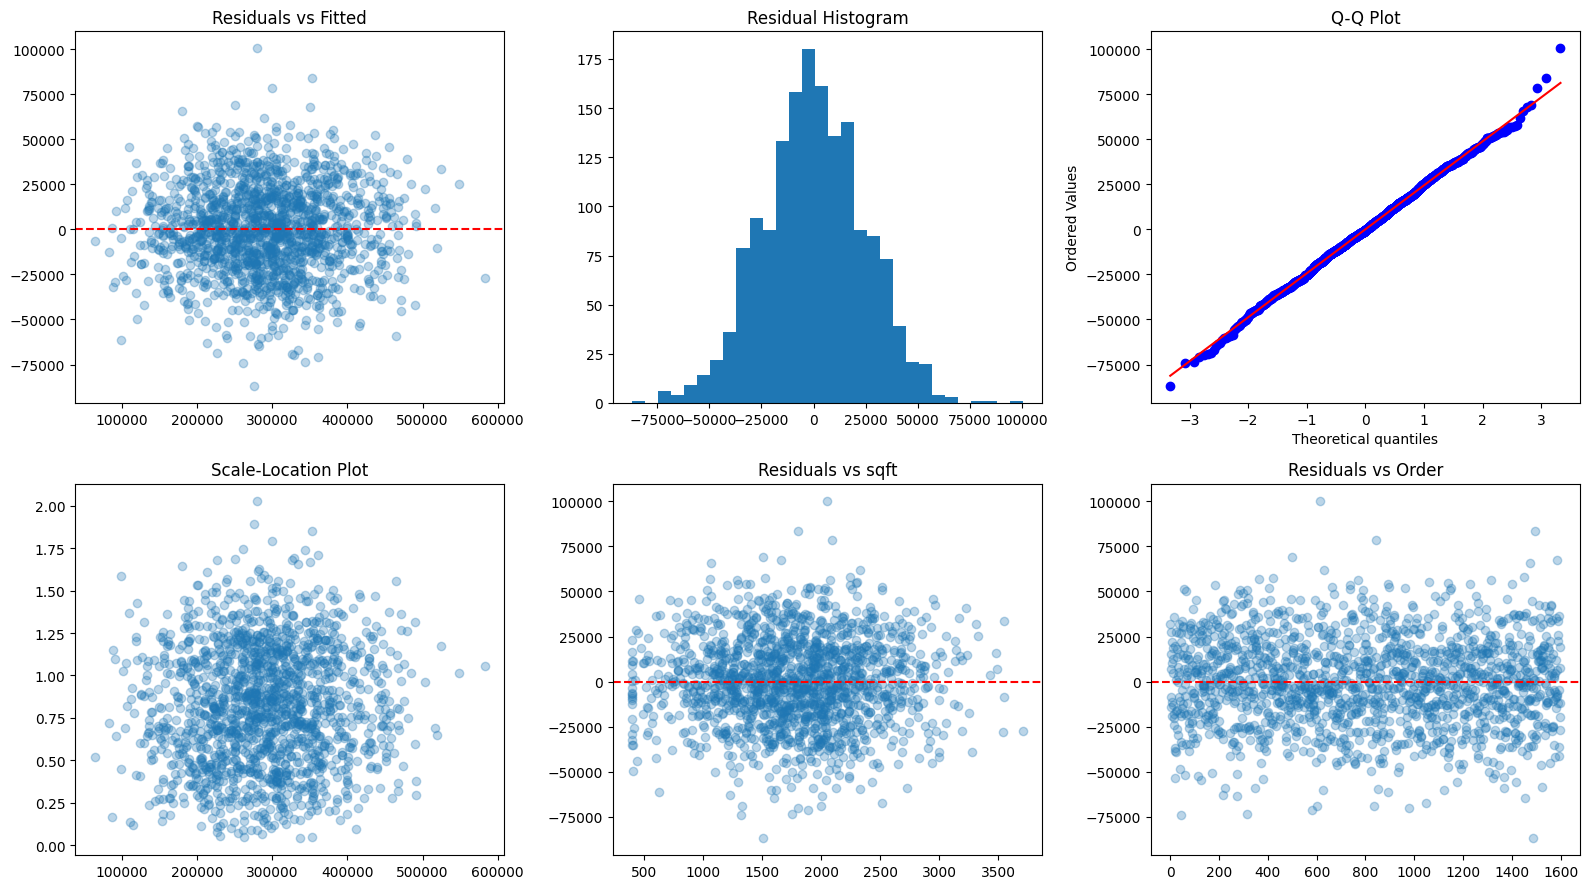

In [12]:
fitted = scratch_model.predict(X_train)
residuals = y_train - fitted
standardized_residuals = residuals / residuals.std()

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes[0,0].scatter(fitted, residuals, alpha=0.3)
axes[0,0].axhline(0, color='red', linestyle='--')
axes[0,0].set_title("Residuals vs Fitted")

axes[0,1].hist(residuals, bins=30)
axes[0,1].set_title("Residual Histogram")

stats.probplot(residuals, dist="norm", plot=axes[0,2])
axes[0,2].set_title("Q-Q Plot")

axes[1,0].scatter(fitted, np.sqrt(np.abs(standardized_residuals)), alpha=0.3)
axes[1,0].set_title("Scale-Location Plot")

axes[1,1].scatter(X_train[:,0], residuals, alpha=0.3)
axes[1,1].axhline(0, color='red', linestyle='--')
axes[1,1].set_title("Residuals vs sqft")

axes[1,2].scatter(range(len(residuals)), residuals, alpha=0.3)
axes[1,2].axhline(0, color='red', linestyle='--')
axes[1,2].set_title("Residuals vs Order")

plt.tight_layout()
print(f"Residual skewness: {stats.skew(residuals):.3f}  (near 0 = roughly symmetric)")
print(f"Residual std: {residuals.std():.2f}")

## 11. Bias-Variance Tradeoff: Polynomial Degree Comparison (Parts 25-26)

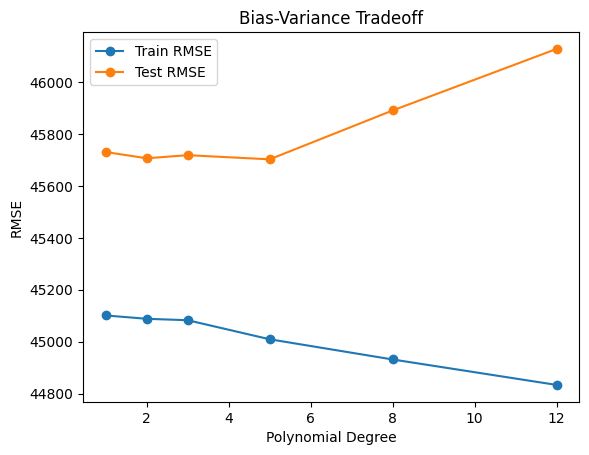

,degree,train_rmse,test_rmse
0,1,45101.1,45730.5
1,2,45088.2,45706.5
2,3,45082.7,45718.4
3,5,45009.4,45702.4
4,8,44931.6,45890.5
5,12,44833.5,46127.6


In [13]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error

X_single = df[["sqft"]].values
y_single = df["price"].values
X_tr, X_te, y_tr, y_te = train_test_split(X_single, y_single, test_size=0.2, random_state=42)

degrees = [1,2,3,5,8,12]
train_rmse, test_rmse = [], []
for d in degrees:
    pipe = make_pipeline(PolynomialFeatures(d), StandardScaler(), LinearRegression())
    pipe.fit(X_tr, y_tr)
    train_rmse.append(np.sqrt(mean_squared_error(y_tr, pipe.predict(X_tr))))
    test_rmse.append(np.sqrt(mean_squared_error(y_te, pipe.predict(X_te))))

results_df = pd.DataFrame({"degree": degrees, "train_rmse": train_rmse, "test_rmse": test_rmse})
display(results_df.round(1))

plt.plot(degrees, train_rmse, marker='o', label='Train RMSE')
plt.plot(degrees, test_rmse, marker='o', label='Test RMSE')
plt.xlabel("Polynomial Degree"); plt.ylabel("RMSE"); plt.legend()
plt.title("Bias-Variance Tradeoff")

## 12. Ridge, Lasso, and Elastic Net Comparison (Parts 15-16)

Using a wider feature set with many noisy, irrelevant features added, to demonstrate Lasso's sparsity.

In [14]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet

# Add 15 irrelevant noise features to the real predictors
n_noise = 15
X_noise = rng.normal(0, 1, (len(X_full), n_noise))
X_augmented = np.hstack([X_full, X_noise])
noise_names = [f"noise_{i}" for i in range(n_noise)]
all_names = feature_names + noise_names

X_tr, X_te, y_tr, y_te = train_test_split(X_augmented, y_full, test_size=0.2, random_state=42)
scaler2 = StandardScaler().fit(X_tr)
X_tr_s, X_te_s = scaler2.transform(X_tr), scaler2.transform(X_te)

# Standardize the target too, so alpha means the same thing across Ridge/Lasso/ElasticNet (Part 17.2)
y_scaler = StandardScaler().fit(y_tr.reshape(-1, 1))
y_tr_s = y_scaler.transform(y_tr.reshape(-1, 1)).ravel()
y_te_s = y_scaler.transform(y_te.reshape(-1, 1)).ravel()

models = {
    "Linear": LinearRegression(),
    "Ridge (alpha=1.0)": Ridge(alpha=1.0),
    "Lasso (alpha=0.01)": Lasso(alpha=0.01, max_iter=5000),
    "ElasticNet (alpha=0.1)": ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=5000),
}

comparison = []
for name, m in models.items():
    m.fit(X_tr_s, y_tr_s)
    test_r2 = m.score(X_te_s, y_te_s)
    n_zero = np.sum(np.abs(m.coef_) < 1e-6)
    comparison.append({"model": name, "test_R2": test_r2, "coefficients_near_zero": n_zero})

display(pd.DataFrame(comparison).round(4))
print(f"\n(Out of {len(all_names)} total features, {n_noise} are pure noise)")
print("Lasso and Elastic Net should zero out most/all noise features; Ridge shrinks but rarely zeros them.")


(Out of 20 total features, 15 are pure noise)
Lasso and Elastic Net should zero out most/all noise features; Ridge shrinks but rarely zeros them.


,model,test_R2,coefficients_near_zero
0,Linear,0.9068,0
1,Ridge (alpha=1.0),0.9068,0
2,Lasso (alpha=0.01),0.9057,14
3,ElasticNet (alpha=0.1),0.8765,15


## 13. Cross-Validation and Hyperparameter Tuning (Parts 17-18)

In [15]:
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV

kf = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(Ridge(alpha=1.0), X_tr_s, y_tr, cv=kf, scoring="neg_root_mean_squared_error")
print(f"RMSE per fold: {np.round(-scores, 1)}")
print(f"Mean RMSE: {-scores.mean():.2f} (+/- {scores.std():.2f})")

param_grid = {"alpha": np.logspace(-2, 4, 20)}
grid_search = GridSearchCV(Ridge(), param_grid, cv=5, scoring="neg_mean_squared_error")
grid_search.fit(X_tr_s, y_tr)
print(f"\nBest alpha found via GridSearchCV: {grid_search.best_params_['alpha']:.4f}")

RMSE per fold: [23738.7 25394.2 24510.6 24398.3 24679.1]
Mean RMSE: 24544.18 (+/- 531.42)

Best alpha found via GridSearchCV: 1.6238


## 14. Full Production Pipeline (Part 19)

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

numeric_features = ["sqft", "bedrooms", "age"]
categorical_features = ["neighborhood"]

numeric_transformer = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
categorical_transformer = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                     ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore"))])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features),
])

full_pipeline = Pipeline([("preprocessor", preprocessor), ("model", Ridge(alpha=grid_search.best_params_['alpha']))])

df_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
full_pipeline.fit(df_train[numeric_features+categorical_features], df_train["price"])
test_predictions = full_pipeline.predict(df_test[numeric_features+categorical_features])

test_r2 = full_pipeline.score(df_test[numeric_features+categorical_features], df_test["price"])
print(f"Pipeline test R2: {test_r2:.4f}")
print("Pipeline correctly handles raw DataFrame input end to end - imputation, scaling, encoding, and prediction.")

Pipeline test R2: 0.9067
Pipeline correctly handles raw DataFrame input end to end - imputation, scaling, encoding, and prediction.


## 15. Segment-Level Error Analysis (Part 29)

In [17]:
results_df = df_test.copy()
results_df["predicted"] = test_predictions
results_df["abs_error"] = np.abs(results_df["price"] - results_df["predicted"])
results_df["pct_error"] = results_df["abs_error"] / results_df["price"]

segment_errors = results_df.groupby("neighborhood").agg(
    n=("abs_error", "size"), mae=("abs_error", "mean"), mape=("pct_error", "mean")
).sort_values("mae", ascending=False)

overall_mae = results_df["abs_error"].mean()
display(segment_errors.round(2))
print(f"\nOverall MAE: {overall_mae:,.2f}")


Overall MAE: 20,119.20


,n,mae,mape
neighborhood,,,
Rural,66,21151.56,0.10
Downtown,132,20488.10,0.07
Suburb,202,19540.84,0.08


## 16. Summary

This workbook implemented and verified, end to end, the core techniques of the Linear Regression module: manual and NumPy OLS (matching exactly), gradient descent (converging to the same solution), a from-scratch statistical inference layer (standard errors, t-tests, the overall F-test, confidence and prediction intervals - built without `statsmodels`), VIF-based multicollinearity detection, leverage and Cook's Distance, a full six-panel residual diagnostic suite, the bias-variance tradeoff via polynomial degree, Ridge/Lasso/Elastic Net comparison (demonstrating Lasso's sparsity on engineered noise features), cross-validation and hyperparameter tuning, a complete production `Pipeline`, and segment-level error analysis.

Every result is computed directly on real (simulated) data - re-run, perturb the data-generating parameters, or extend any section to deepen the intuition built throughout the module.

**Kajola Gbenga**
*Data Scientist & AI Engineer*